# 01 — Exploration des données Home Credit

**Objectif** : comprendre les demandes de prêt avant de modéliser, et décider des règles de préparation des données.

Questions traitées :
1. Que contient une ligne, et que veut dire la cible `TARGET` ?
2. À quel point les classes sont-elles déséquilibrées, et pourquoi l'accuracy est-elle trompeuse ?
3. Quelles colonnes ont des valeurs manquantes, et l'absence d'une valeur est-elle une information ?
4. Quelles valeurs sont aberrantes ou mal codées ?
5. Quelles variables sont liées au défaut de paiement ?
6. Le sexe est-il prédictif, et d'autres variables le reflètent-elles indirectement ?
7. Que peut apporter l'historique de crédit (`bureau.csv`) ?

**Règle suivie** : à partir de la section 2, tout est calculé sur le **jeu d'apprentissage uniquement** (80 % des prêts).
Le jeu de test reste de côté jusqu'à l'évaluation finale, pour qu'aucune décision ne soit influencée par lui.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from matplotlib.ticker import MultipleLocator, PercentFormatter
from sklearn.metrics import accuracy_score, recall_score
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 200)

# Couleurs : bleu = rembourse sans incident / baisse le risque, orange = défaut / hausse le risque
BLEU, ORANGE, VERT_D_EAU, JAUNE = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GRIS = "#8a8984"
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.grid": True, "grid.color": "#e8e7e2",
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "lines.linewidth": 2,
})


def afficher(table, formats=None):
    """Affiche un tableau : colonnes « taux » et « part » en %, les autres en nombres entiers."""
    formats_auto = {c: "{:.1%}" if str(c).startswith(("taux", "part")) else "{:,.0f}"
                    for c in table.select_dtypes("number").columns}
    formats_auto.update(formats or {})
    return table.style.format(formats_auto)

## 1. Chargement et structure des données

In [2]:
DOSSIER_RAW = Path("..") / "data" / "raw"
app = pd.read_csv(DOSSIER_RAW / "application_train.csv")

print(f"{len(app):,} demandes de prêt, {app.shape[1]} colonnes")
print("Une ligne par client :", app["SK_ID_CURR"].is_unique)

numeriques = app.select_dtypes("number").columns.drop(["SK_ID_CURR", "TARGET"])
textes = app.select_dtypes(exclude="number").columns
binaires = [c for c in numeriques if app[c].nunique() == 2]
print(f"{len(numeriques)} colonnes numériques (dont {len(binaires)} indicateurs 0/1) et {len(textes)} colonnes texte")

307,511 demandes de prêt, 122 colonnes
Une ligne par client : True


104 colonnes numériques (dont 32 indicateurs 0/1) et 16 colonnes texte


Le fichier `HomeCredit_columns_description.csv` décrit chaque colonne. Il est encodé en latin-1 (et non en UTF-8),
d'où le paramètre `encoding`.

In [3]:
description = pd.read_csv(DOSSIER_RAW / "HomeCredit_columns_description.csv", encoding="latin-1")
description = (description[description["Table"] == "application_{train|test}.csv"]
               .set_index("Row")[["Description"]])


def decrire(*colonnes):
    return description.loc[list(colonnes)]


decrire("TARGET", "EXT_SOURCE_1", "DAYS_BIRTH", "DAYS_EMPLOYED", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE")

,Description
Row,
TARGET,"Target variable (1 - client with payment difficulties: he/she had late payment more than X days on at least one of the first Y installments of the loan in our sample, 0 - all other cases)"
EXT_SOURCE_1,Normalized score from external data source
DAYS_BIRTH,Client's age in days at the time of application
DAYS_EMPLOYED,How many days before the application the person started current employment
AMT_CREDIT,Credit amount of the loan
AMT_ANNUITY,Loan annuity
AMT_GOODS_PRICE,For consumer loans it is the price of the goods for which the loan is given


- Une ligne = **une demande de prêt d'un client** (`SK_ID_CURR` est unique) : pas de regroupement à faire, contrairement aux ventes DVF du projet 1.
- **`TARGET` = 1** : le client a eu un retard de paiement de plus de X jours sur au moins une des Y premières échéances. Home Credit ne précise pas X et Y.
- Les colonnes `DAYS_*` sont des **nombres de jours avant la demande**, donc négatifs (section 4).
- `EXT_SOURCE_1` à `3` sont des **scores normalisés venant de sources externes** (bureaux de crédit). Leur calcul n'est pas documenté.

## 2. La cible : des classes très déséquilibrées

In [4]:
compte = app["TARGET"].value_counts().sort_index()
cible = pd.DataFrame({"prets": compte, "part": compte / len(app)})
cible.index = ["0 : pas d'incident", "1 : difficultés de paiement"]
afficher(cible)

,prets,part
0 : pas d'incident,"282,686",91.9%
1 : difficultés de paiement,"24,825",8.1%


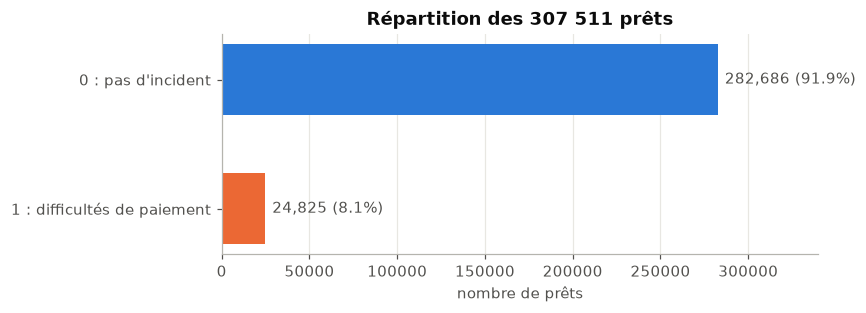

In [5]:
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh(cible.index[::-1], cible["prets"][::-1], color=[ORANGE, BLEU], height=0.55)
for y, (n, p) in enumerate(zip(cible["prets"][::-1], cible["part"][::-1])):
    ax.text(n + 4000, y, f"{n:,} ({p:.1%})", va="center", color="#52514e")
ax.set_xlim(0, 340_000)
ax.set_title("Répartition des 307 511 prêts")
ax.set_xlabel("nombre de prêts")
ax.grid(axis="y", visible=False)
plt.show()

**Le piège de l'accuracy** : un « modèle » qui prédit que personne ne fera défaut a raison dans 92 % des cas,
mais il ne détecte aucun défaut, et une banque qui l'appliquerait accorderait tous les prêts.

In [6]:
personne_ne_fait_defaut = np.zeros(len(app), dtype=int)
print(f"Accuracy : {accuracy_score(app['TARGET'], personne_ne_fait_defaut):.1%}")
print(f"Part des défauts détectés (rappel) : {recall_score(app['TARGET'], personne_ne_fait_defaut):.0%}")

Accuracy : 91.9%
Part des défauts détectés (rappel) : 0%


**Conséquences pour la suite** :
- métrique principale **ROC AUC** (qualité du classement des clients par risque), complétée par la PR AUC et un coût métier ;
- **découpage stratifié** : même proportion de défauts dans l'apprentissage et dans le test ;
- comparer plus tard l'absence de correction et la **pondération des classes**.

### Découpage apprentissage / test

Les demandes ne sont pas datées : le découpage est aléatoire et stratifié. `random_state=42` le rend reproductible :
`src/prepare_data.py` refera exactement le même découpage.

In [7]:
train, test = train_test_split(app, test_size=0.2, stratify=app["TARGET"], random_state=42)
afficher(pd.DataFrame({
    "prets": [len(train), len(test)],
    "defauts": [train["TARGET"].sum(), test["TARGET"].sum()],
    "taux_defaut": [train["TARGET"].mean(), test["TARGET"].mean()],
}, index=["apprentissage (80 %)", "test (20 %)"]))

,prets,defauts,taux_defaut
apprentissage (80 %),"246,008","19,860",8.1%
test (20 %),"61,503","4,965",8.1%


In [8]:
del test, app  # le jeu de test n'est plus utilisé dans ce notebook
TAUX_MOYEN = train["TARGET"].mean()
MOYENNE = f"(pointillés : moyenne {TAUX_MOYEN:.1%})"


def taux_defaut(groupes, donnees=None):
    """Nombre de prêts et taux de défaut par groupe (jeu d'apprentissage)."""
    donnees = train if donnees is None else donnees
    return (donnees.groupby(groupes, observed=True, dropna=False)["TARGET"]
            .agg(prets="size", taux_defaut="mean"))


def barres_taux(ax, table, titre):
    """Barres horizontales du taux de défaut, avec le taux moyen en pointillés."""
    table = table.sort_values("taux_defaut")
    ax.barh(table.index.astype(str), table["taux_defaut"], color=BLEU, height=0.6)
    ax.axvline(TAUX_MOYEN, color=GRIS, linestyle="--", linewidth=1.2)
    ax.xaxis.set_major_locator(MultipleLocator(0.02))
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_title(titre, loc="left")
    ax.grid(axis="y", visible=False)

## 3. Valeurs manquantes

In [9]:
manquants = train.isna().mean().sort_values(ascending=False)
logement = [c for c in train.columns if c.endswith(("_AVG", "_MODE", "_MEDI"))]

print(f"{(manquants > 0).sum()} colonnes sur {train.shape[1]} ont des valeurs manquantes, "
      f"dont {(manquants > 0.5).sum()} à plus de 50 %")
print(f"{len(logement)} colonnes décrivent l'immeuble du client : "
      f"de {manquants[logement].min():.0%} à {manquants[logement].max():.0%} de valeurs manquantes")

67 colonnes sur 122 ont des valeurs manquantes, dont 41 à plus de 50 %
47 colonnes décrivent l'immeuble du client : de 47% à 70% de valeurs manquantes


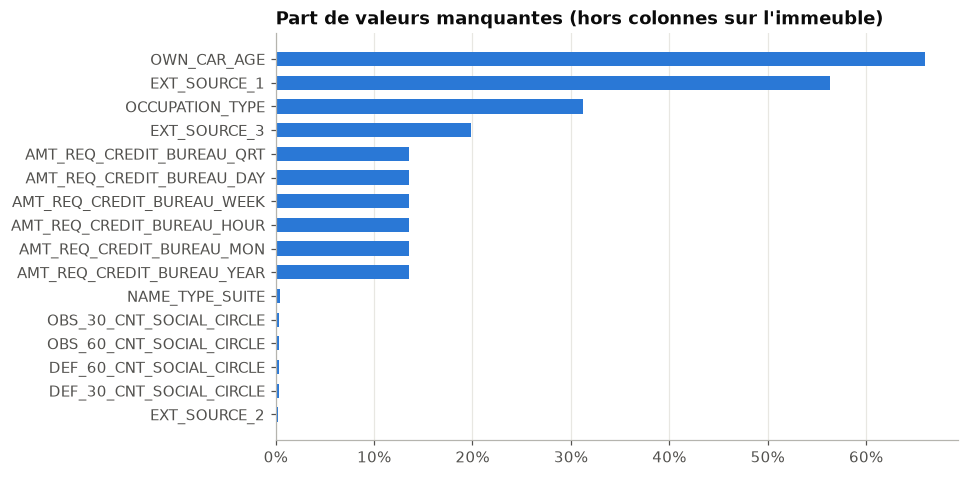

In [10]:
hors_logement = manquants.drop(logement)
hors_logement = hors_logement[hors_logement > 0.001].sort_values()

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(hors_logement.index, hors_logement, color=BLEU, height=0.6)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_title("Part de valeurs manquantes (hors colonnes sur l'immeuble)", loc="left")
ax.grid(axis="y", visible=False)
plt.show()

**Les colonnes sur l'immeuble** (surface des parties communes, nombre d'étages, ascenseurs…) existent en trois versions :
moyenne (`_AVG`), mode (`_MODE`) et médiane (`_MEDI`) de l'immeuble. Les trois versions sont presque identiques :

In [11]:
moyennes = [c for c in logement if c.endswith("_AVG")]
correlations = pd.DataFrame({
    "AVG ~ MEDI": [train[c].corr(train[c.replace("_AVG", "_MEDI")]) for c in moyennes],
    "AVG ~ MODE": [train[c].corr(train[c.replace("_AVG", "_MODE")]) for c in moyennes],
}, index=moyennes)
print(f"{len(moyennes)} variables en triple : corrélation minimale "
      f"{correlations['AVG ~ MEDI'].min():.3f} (médiane) et {correlations['AVG ~ MODE'].min():.3f} (mode)")

14 variables en triple : corrélation minimale 0.989 (médiane) et 0.967 (mode)


→ On ne garde que la version `_AVG` (+ `TOTALAREA_MODE` et les 4 colonnes texte en `_MODE`, qui n'ont pas d'équivalent `_AVG`) :
**28 colonnes redondantes en moins**.

### L'absence d'une valeur est-elle une information ?

Si les clients sans valeur ont un taux de défaut différent, remplacer simplement les valeurs manquantes par la médiane
ferait perdre cette information. Il faut alors ajouter un indicateur « valeur manquante ».

In [12]:
lignes = []
for colonne in ["EXT_SOURCE_1", "EXT_SOURCE_3", "OCCUPATION_TYPE", "AMT_REQ_CREDIT_BUREAU_YEAR", "OWN_CAR_AGE"]:
    manque = train[colonne].isna()
    lignes.append({
        "variable": colonne,
        "part_manquante": manque.mean(),
        "taux_defaut_si_manquante": train.loc[manque, "TARGET"].mean(),
        "taux_defaut_si_renseignee": train.loc[~manque, "TARGET"].mean(),
    })
afficher(pd.DataFrame(lignes).set_index("variable"))

,part_manquante,taux_defaut_si_manquante,taux_defaut_si_renseignee
variable,,,
EXT_SOURCE_1,56.3%,8.5%,7.5%
EXT_SOURCE_3,19.8%,9.3%,7.8%
OCCUPATION_TYPE,31.3%,6.5%,8.8%
AMT_REQ_CREDIT_BUREAU_YEAR,13.5%,10.3%,7.7%
OWN_CAR_AGE,66.0%,8.5%,7.3%


In [13]:
# OWN_CAR_AGE (âge de la voiture) manque presque exactement quand le client n'a pas de voiture
pd.crosstab(train["FLAG_OWN_CAR"], train["OWN_CAR_AGE"].isna().map({True: "âge manquant", False: "âge renseigné"}))

OWN_CAR_AGE,âge manquant,âge renseigné
FLAG_OWN_CAR,,
N,162413,0
Y,5,83590


- **Oui, l'absence est informative** : sans score `EXT_SOURCE_3`, le taux de défaut passe de 7,8 % à 9,3 % ;
  sans demande au bureau de crédit renseignée (`AMT_REQ_CREDIT_BUREAU_YEAR`), il monte à 10,3 %.
- **Certaines absences sont logiques** : `OWN_CAR_AGE` manque parce que le client n'a pas de voiture (à 5 clients près).
  Ce n'est pas une donnée perdue.
- **Décision** : pour la régression logistique, imputation par la médiane **et** indicateur de valeur manquante.
  XGBoost gère les valeurs manquantes tout seul (il apprend de quel côté de chaque coupure les envoyer).

## 4. Valeurs aberrantes et mal codées

### 4.1 Les dates sont des nombres de jours négatifs

`DAYS_BIRTH = -12 000` veut dire « né 12 000 jours avant la demande ». On convertit en années, avec un signe positif.

In [14]:
train[["DAYS_BIRTH", "DAYS_EMPLOYED", "DAYS_REGISTRATION", "DAYS_ID_PUBLISH", "DAYS_LAST_PHONE_CHANGE"]].describe().round(0)

,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,DAYS_LAST_PHONE_CHANGE
count,246008.0,246008.0,246008.0,246008.0,246007.0
mean,-16030.0,63581.0,-4990.0,-2994.0,-963.0
std,4363.0,141082.0,3525.0,1508.0,827.0
min,-25229.0,-17912.0,-24672.0,-7197.0,-4292.0
25%,-19673.0,-2762.0,-7480.0,-4298.0,-1569.0
50%,-15744.0,-1215.0,-4505.0,-3255.0,-757.0
75%,-12401.0,-291.0,-2015.0,-1720.0,-273.0
max,-7489.0,365243.0,0.0,0.0,0.0


### 4.2 `DAYS_EMPLOYED = 365 243` : 1 000 ans d'ancienneté

Le maximum de `DAYS_EMPLOYED` est **positif** : 365 243 jours, soit 1 000 ans. C'est un code, pas une ancienneté.

In [15]:
anomalie = train["DAYS_EMPLOYED"] == 365243
print(f"{anomalie.sum():,} prêts ({anomalie.mean():.1%}) ont DAYS_EMPLOYED = 365 243")
print("Type de revenu de ces clients :", train.loc[anomalie, "NAME_INCOME_TYPE"].value_counts().to_dict())
print("Sont-ce exactement les clients avec ORGANIZATION_TYPE = 'XNA' ?",
      (anomalie == (train["ORGANIZATION_TYPE"] == "XNA")).all())
afficher(taux_defaut(anomalie.map({True: "code 365 243 (retraités, chômeurs)", False: "ancienneté réelle"})))

44,143 prêts (17.9%) ont DAYS_EMPLOYED = 365 243
Type de revenu de ces clients : {'Pensioner': 44126, 'Unemployed': 17}
Sont-ce exactement les clients avec ORGANIZATION_TYPE = 'XNA' ? True


,prets,taux_defaut
DAYS_EMPLOYED,,
ancienneté réelle,"201,865",8.7%
"code 365 243 (retraités, chômeurs)","44,143",5.4%


- Le code 365 243 signifie **« pas d'emploi »** : ce sont les retraités (44 126) et les chômeurs (17), et exactement les clients
  dont l'employeur (`ORGANIZATION_TYPE`) vaut « XNA ».
- Leur taux de défaut est **plus faible** (5,4 % contre 8,7 %) : c'est une vraie information.
- **Décision** : remplacer 365 243 par une valeur manquante dans l'ancienneté, et créer un indicateur `SANS_EMPLOI`.
  Laisser 365 243 tel quel ferait croire à la régression logistique que ces clients ont une ancienneté énorme.

Conversion de toutes les dates en années (ce code sera repris dans `src/prepare_data.py`) :

In [16]:
JOURS_EN_ANNEES = {
    "DAYS_BIRTH": "AGE",
    "DAYS_EMPLOYED": "ANCIENNETE_EMPLOI",
    "DAYS_REGISTRATION": "ANNEES_DEPUIS_CHGT_ENREGISTREMENT",
    "DAYS_ID_PUBLISH": "ANNEES_DEPUIS_CHGT_PIECE_IDENTITE",
    "DAYS_LAST_PHONE_CHANGE": "ANNEES_DEPUIS_CHGT_TELEPHONE",
}


def convertir_dates(donnees):
    """Jours négatifs → années positives, et code 365 243 → pas d'emploi."""
    donnees = donnees.copy()
    donnees["SANS_EMPLOI"] = (donnees["DAYS_EMPLOYED"] == 365243).astype(int)
    donnees["DAYS_EMPLOYED"] = donnees["DAYS_EMPLOYED"].replace(365243, np.nan)
    for jours, annees in JOURS_EN_ANNEES.items():
        donnees[annees] = donnees[jours].abs() / 365.25  # tous les jours sont <= 0
    return donnees.drop(columns=list(JOURS_EN_ANNEES))


train = convertir_dates(train)
train[list(JOURS_EN_ANNEES.values())].describe().round(1)

,AGE,ANCIENNETE_EMPLOI,ANNEES_DEPUIS_CHGT_ENREGISTREMENT,ANNEES_DEPUIS_CHGT_PIECE_IDENTITE,ANNEES_DEPUIS_CHGT_TELEPHONE
count,246008.0,201865.0,246008.0,246008.0,246007.0
mean,43.9,6.5,13.7,8.2,2.6
std,11.9,6.4,9.6,4.1,2.3
min,20.5,0.0,0.0,0.0,0.0
25%,34.0,2.1,5.5,4.7,0.7
50%,43.1,4.5,12.3,8.9,2.1
75%,53.9,8.7,20.5,11.8,4.3
max,69.1,49.0,67.5,19.7,11.8


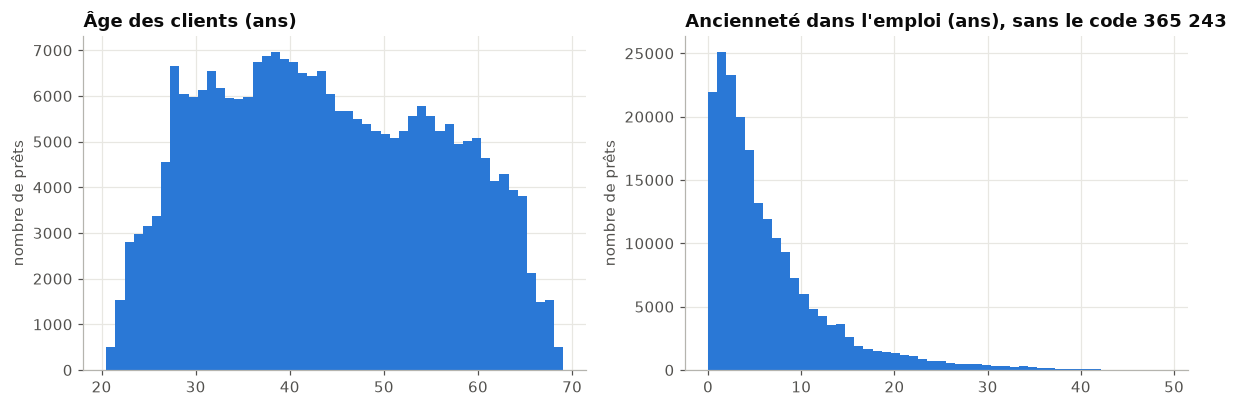

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(train["AGE"], bins=50, color=BLEU)
axes[0].set_title("Âge des clients (ans)", loc="left")
axes[1].hist(train["ANCIENNETE_EMPLOI"].dropna(), bins=50, color=BLEU)
axes[1].set_title("Ancienneté dans l'emploi (ans), sans le code 365 243", loc="left")
for ax in axes:
    ax.set_ylabel("nombre de prêts")
plt.tight_layout()
plt.show()

### 4.3 Revenus extrêmes

In [18]:
print(train["AMT_INCOME_TOTAL"].describe(percentiles=[0.01, 0.5, 0.99, 0.999]).round(0).to_string())
print("\n5 plus gros revenus :", train["AMT_INCOME_TOTAL"].nlargest(5).astype(int).tolist())
train.loc[[train["AMT_INCOME_TOTAL"].idxmax()], ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "NAME_INCOME_TYPE", "TARGET"]]

count       246008.0
mean        168853.0
std         258961.0
min          25650.0
1%           45000.0
50%         147600.0
99%         472500.0
99.9%       900000.0
max      117000000.0

5 plus gros revenus : [117000000, 18000090, 9000000, 6750000, 4500000]


,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,NAME_INCOME_TYPE,TARGET
12840,117000000.0,562491.0,26194.5,Working,1


- Le plus gros revenu (117 millions) vaut **près de 800 fois le revenu médian**, pour un crédit de 562 000 seulement,
  et ce client a eu des difficultés de paiement : c'est très probablement une erreur de saisie.
- **Décision** : on ne supprime pas ces lignes. En production, la banque doit aussi répondre aux dossiers mal saisis.
  On utilisera plutôt le **logarithme des montants** pour la régression logistique, ce qui réduit le poids des extrêmes.
  Les arbres et XGBoost n'y sont pas sensibles : ils ne regardent que l'ordre des valeurs.
- Les montants sont dans une monnaie non précisée par Home Credit : on ne les lit pas comme des euros.

### 4.4 Modalités rares et colonnes presque constantes

In [19]:
for colonne in ["CODE_GENDER", "NAME_FAMILY_STATUS", "NAME_INCOME_TYPE"]:
    print(colonne, train[colonne].value_counts().to_dict())

minoritaire = {c: train[c].value_counts(normalize=True).min() for c in binaires}
quasi_constantes = sorted((c for c, part in minoritaire.items() if part < 0.001), key=minoritaire.get)
print(f"\n{len(quasi_constantes)} indicateurs 0/1 dont la valeur minoritaire concerne moins de 0,1 % des prêts :")
print(quasi_constantes)

CODE_GENDER {'F': 161887, 'M': 84119, 'XNA': 2}
NAME_FAMILY_STATUS {'Married': 157153, 'Single / not married': 36359, 'Civil marriage': 23812, 'Separated': 15840, 'Widow': 12842, 'Unknown': 2}
NAME_INCOME_TYPE {'Working': 127043, 'Commercial associate': 57273, 'Pensioner': 44134, 'State servant': 17518, 'Unemployed': 17, 'Student': 11, 'Businessman': 9, 'Maternity leave': 3}

10 indicateurs 0/1 dont la valeur minoritaire concerne moins de 0,1 % des prêts :
['FLAG_MOBIL', 'FLAG_DOCUMENT_12', 'FLAG_DOCUMENT_10', 'FLAG_DOCUMENT_2', 'FLAG_DOCUMENT_4', 'FLAG_DOCUMENT_7', 'FLAG_DOCUMENT_17', 'FLAG_DOCUMENT_21', 'FLAG_DOCUMENT_20', 'FLAG_DOCUMENT_19']


- **Modalités rares** : 2 clients avec le sexe « XNA », 2 avec la situation familiale « Unknown », moins de 20 étudiants,
  chefs d'entreprise ou congés maternité. Un modèle ne peut rien apprendre de fiable sur 3 personnes.
  **Décision** : regrouper les modalités rares dans une modalité « autre » au moment du one-hot encoding
  (option `min_frequency` de `OneHotEncoder` dans scikit-learn).
- **Colonnes presque constantes** : `FLAG_MOBIL` (un seul client sans téléphone portable) et 9 indicateurs de documents fournis
  (`FLAG_DOCUMENT_*`). **Décision** : les retirer, elles n'apportent presque aucune information.

## 5. Quelles variables numériques sont liées au défaut ?

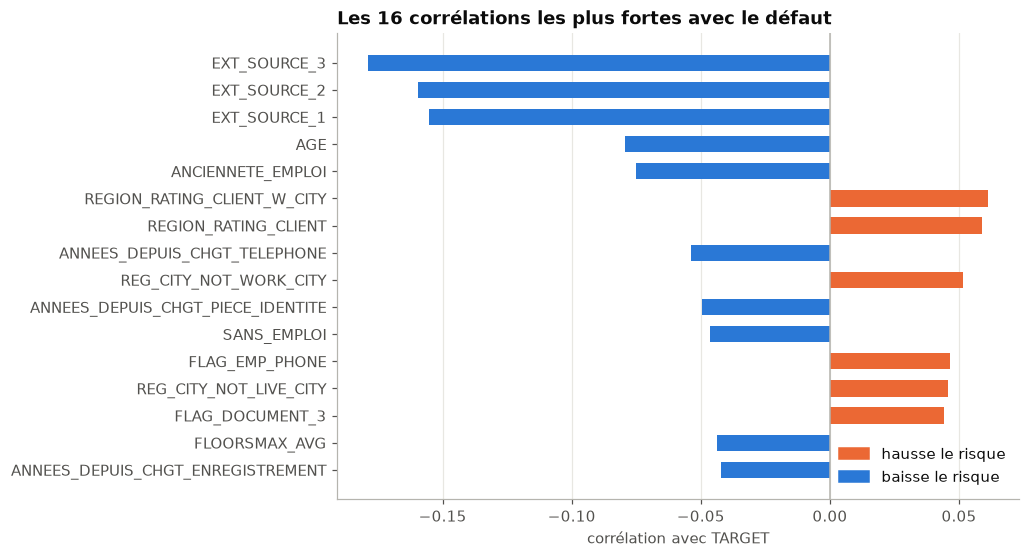

In [20]:
# Sans les versions _MEDI et _MODE des colonnes sur l'immeuble, qui doublent les _AVG (section 3)
variables_num = train.select_dtypes("number").drop(columns=["SK_ID_CURR", "TARGET"])
variables_num = variables_num.drop(columns=[c for c in variables_num if c.endswith(("_MEDI", "_MODE"))])
correlation = variables_num.corrwith(train["TARGET"]).dropna()
plus_fortes = correlation.reindex(correlation.abs().sort_values().index).tail(16)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(plus_fortes.index, plus_fortes, color=[ORANGE if r > 0 else BLEU for r in plus_fortes], height=0.6)
ax.axvline(0, color="#b5b4ae", linewidth=1)
ax.set_title("Les 16 corrélations les plus fortes avec le défaut", loc="left")
ax.set_xlabel("corrélation avec TARGET")
ax.legend(handles=[Patch(color=ORANGE, label="hausse le risque"), Patch(color=BLEU, label="baisse le risque")],
          loc="lower right", frameon=False)
ax.grid(axis="y", visible=False)
plt.show()

- Aucune variable n'est fortement corrélée au défaut : la plus forte, `EXT_SOURCE_3`, est à **−0,18**.
  Chaque variable seule prédit mal ; c'est leur combinaison qui fera le modèle.
- Les **trois scores externes** dominent, suivis de l'**âge** (les plus jeunes font plus souvent défaut),
  de l'**ancienneté dans l'emploi** et de la **note de la région** (`REGION_RATING_CLIENT`, de 1 à 3).
- Une corrélation ne mesure qu'un lien linéaire : on regarde donc aussi le taux de défaut par tranche.

### Les scores externes

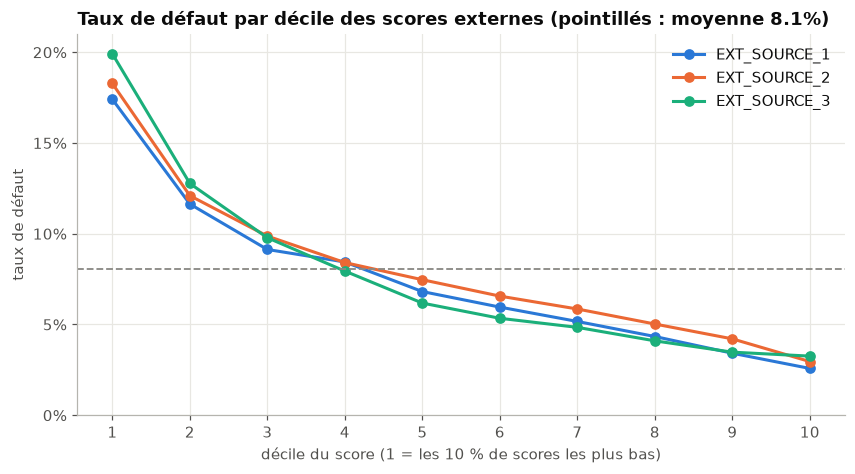

,taux_d1,taux_d2,taux_d3,taux_d4,taux_d5,taux_d6,taux_d7,taux_d8,taux_d9,taux_d10
EXT_SOURCE_1,17.4%,11.6%,9.1%,8.4%,6.8%,6.0%,5.2%,4.3%,3.4%,2.6%
EXT_SOURCE_2,18.3%,12.1%,9.9%,8.4%,7.5%,6.6%,5.9%,5.0%,4.2%,3.0%
EXT_SOURCE_3,19.9%,12.8%,9.8%,7.9%,6.2%,5.3%,4.8%,4.1%,3.5%,3.3%


In [21]:
scores = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]
deciles = pd.DataFrame({
    score: train.groupby(pd.qcut(train[score], 10, labels=range(1, 11)), observed=True)["TARGET"].mean()
    for score in scores
})

fig, ax = plt.subplots(figsize=(9, 4.5))
for score, couleur in zip(scores, [BLEU, ORANGE, VERT_D_EAU]):
    ax.plot(deciles.index, deciles[score], marker="o", markersize=6, color=couleur, label=score)
ax.axhline(TAUX_MOYEN, color=GRIS, linestyle="--", linewidth=1.2)
ax.yaxis.set_major_locator(MultipleLocator(0.05))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0, 0.21)
ax.set_xticks(range(1, 11))
ax.set_xlabel("décile du score (1 = les 10 % de scores les plus bas)")
ax.set_ylabel("taux de défaut")
ax.set_title(f"Taux de défaut par décile des scores externes {MOYENNE}", loc="left")
ax.legend(frameon=False)
plt.show()

afficher(deciles.T.rename(columns=lambda d: f"taux_d{d}"))

In [22]:
print("Corrélation entre les scores externes et l'âge :")
train[scores + ["AGE"]].corr().round(2)

Corrélation entre les scores externes et l'âge :


,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,AGE
EXT_SOURCE_1,1.00,0.21,0.19,0.60
EXT_SOURCE_2,0.21,1.00,0.11,0.09
EXT_SOURCE_3,0.19,0.11,1.00,0.21
AGE,0.60,0.09,0.21,1.00


- Chaque score **classe très bien les clients** : de 17-20 % de défauts dans le premier décile à 3 % dans le dernier,
  soit un risque **6 fois plus élevé** chez les 10 % de scores les plus bas.
- Les trois scores sont peu corrélés entre eux (0,1 à 0,2) : ils apportent des informations différentes.
- `EXT_SOURCE_1` est corrélé à **0,60 avec l'âge** : il intègre probablement l'âge du client.
- C'est pourquoi la **moyenne des trois scores** servira de baseline dans le notebook 02 : un score qui existe déjà, sans modèle.

### L'âge

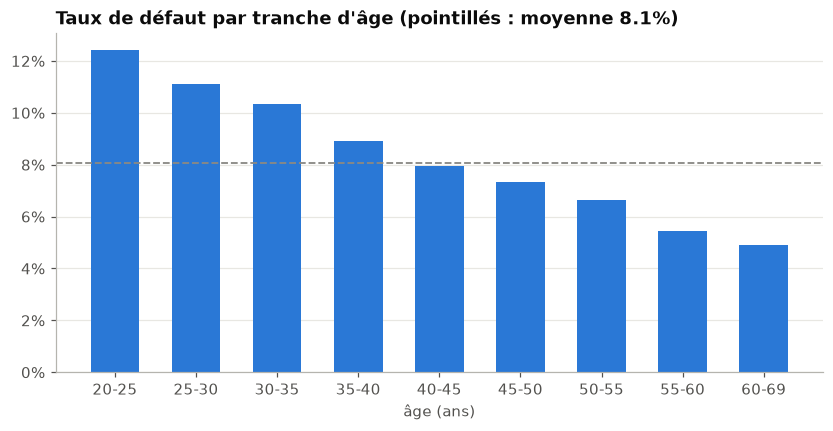

,prets,taux_defaut
AGE,,
20-25,"9,841",12.4%
25-30,"26,440",11.1%
30-35,"31,621",10.3%
35-40,"34,237",8.9%
40-45,"33,135",7.9%
45-50,"28,147",7.3%
50-55,"28,004",6.6%
55-60,"26,485",5.5%
60-69,"28,098",4.9%


In [23]:
tranches_age = pd.cut(train["AGE"], [20, 25, 30, 35, 40, 45, 50, 55, 60, 70],
                      labels=["20-25", "25-30", "30-35", "35-40", "40-45", "45-50", "50-55", "55-60", "60-69"])
par_age = taux_defaut(tranches_age)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(par_age.index.astype(str), par_age["taux_defaut"], color=BLEU, width=0.6)
ax.axhline(TAUX_MOYEN, color=GRIS, linestyle="--", linewidth=1.2)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("âge (ans)")
ax.set_title(f"Taux de défaut par tranche d'âge {MOYENNE}", loc="left")
ax.grid(axis="x", visible=False)
plt.show()
afficher(par_age)

Le taux de défaut baisse régulièrement avec l'âge : **12,4 % avant 25 ans, 4,9 % après 60 ans**.
Le lien est monotone, une régression logistique pourra donc le capter avec un seul coefficient.

## 6. Variables catégorielles

In [24]:
cardinalite = train.select_dtypes(exclude="number").nunique().sort_values(ascending=False)
cardinalite.to_frame("modalites").T

,ORGANIZATION_TYPE,OCCUPATION_TYPE,NAME_INCOME_TYPE,NAME_TYPE_SUITE,WALLSMATERIAL_MODE,WEEKDAY_APPR_PROCESS_START,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,NAME_EDUCATION_TYPE,FONDKAPREMONT_MODE,HOUSETYPE_MODE,CODE_GENDER,FLAG_OWN_CAR,NAME_CONTRACT_TYPE,FLAG_OWN_REALTY,EMERGENCYSTATE_MODE
modalites,58,18,8,7,7,7,6,6,5,4,3,3,2,2,2,2


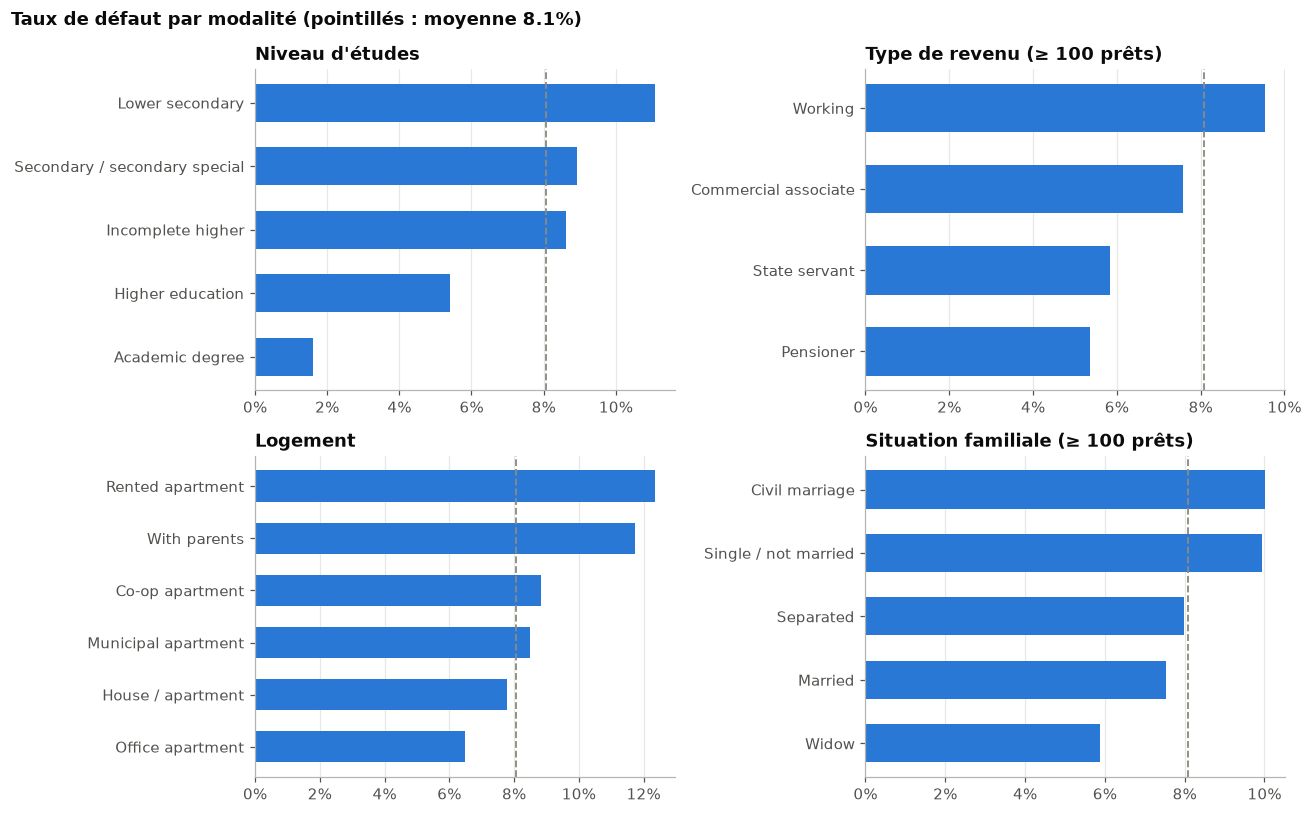

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
for ax, (colonne, titre) in zip(axes.flat, [
    ("NAME_EDUCATION_TYPE", "Niveau d'études"),
    ("NAME_INCOME_TYPE", "Type de revenu (≥ 100 prêts)"),
    ("NAME_HOUSING_TYPE", "Logement"),
    ("NAME_FAMILY_STATUS", "Situation familiale (≥ 100 prêts)"),
]):
    table = taux_defaut(colonne)
    barres_taux(ax, table[table["prets"] >= 100], titre)
fig.suptitle(f"Taux de défaut par modalité {MOYENNE}", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

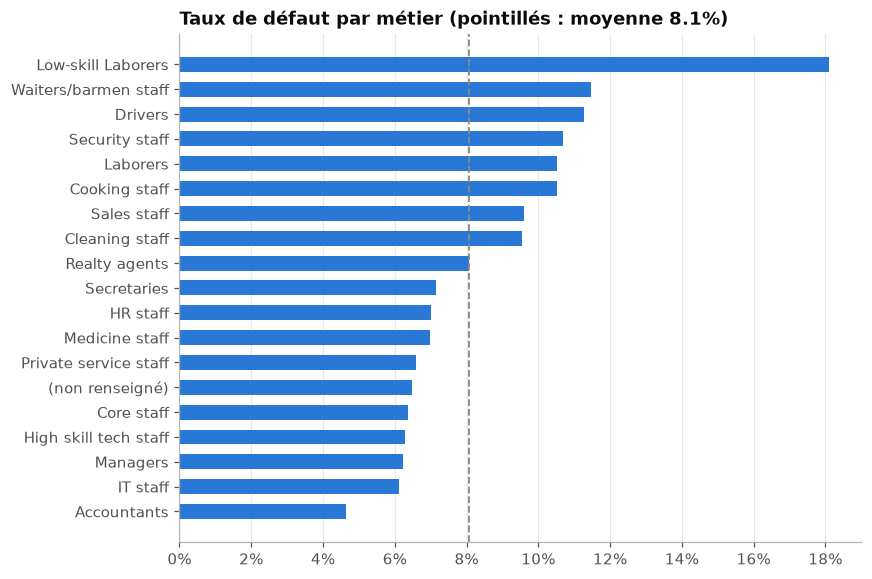

In [26]:
metiers = taux_defaut(train["OCCUPATION_TYPE"].fillna("(non renseigné)"))
fig, ax = plt.subplots(figsize=(8, 6))
barres_taux(ax, metiers, f"Taux de défaut par métier {MOYENNE}")
plt.show()

- **Études** : 5,4 % de défauts avec un diplôme du supérieur, 11,1 % avec le niveau collège (« Lower secondary »).
- **Revenu** : les fonctionnaires (5,9 %) et les retraités (5,4 %) remboursent mieux que les salariés (9,5 %).
- **Logement** : vivre chez ses parents (11,7 %) ou en location (12,3 %) va avec plus de défauts.
- **Métier** : de 4,6 % (comptables) à 18,1 % (ouvriers peu qualifiés). Les clients sans métier renseigné
  sont à 57 % des retraités, d'où un taux bas (6,5 %).
- **Encodage** : le one-hot encoding reste raisonnable, même pour `ORGANIZATION_TYPE` (58 modalités) : avec 246 000 prêts,
  58 colonnes de plus ne posent pas problème. Les modalités rares seront regroupées (section 4.4).

## 7. Le sexe : prédictif, mais exclu du modèle

Le README exclut `CODE_GENDER` pour des raisons éthiques et réglementaires. Vérifions ce que ce choix implique.

In [27]:
sans_xna = train[train["CODE_GENDER"] != "XNA"]
afficher(taux_defaut("CODE_GENDER", sans_xna))

,prets,taux_defaut
CODE_GENDER,,
F,"161,887",7.0%
M,"84,119",10.1%


In [28]:
proxy = (sans_xna.groupby("OCCUPATION_TYPE")
         .agg(prets=("TARGET", "size"),
              part_hommes=("CODE_GENDER", lambda s: (s == "M").mean()),
              taux_defaut=("TARGET", "mean"))
         .sort_values("part_hommes"))
print(f"Part d'hommes parmi tous les clients : {(sans_xna['CODE_GENDER'] == 'M').mean():.0%}")
print("Part de propriétaires d'une voiture :",
      sans_xna.groupby("CODE_GENDER")["FLAG_OWN_CAR"].apply(lambda s: f"{(s == 'Y').mean():.0%}").to_dict())
afficher(proxy)

Part d'hommes parmi tous les clients : 34%
Part de propriétaires d'une voiture : {'F': '22%', 'M': '57%'}


,prets,part_hommes,taux_defaut
OCCUPATION_TYPE,,,
Medicine staff,"6,871",2.9%,7.0%
Accountants,"7,882",2.9%,4.6%
Secretaries,"1,047",4.2%,7.2%
Private service staff,"2,094",4.3%,6.6%
HR staff,443,6.8%,7.0%
Cleaning staff,"3,741",7.3%,9.5%
Realty agents,594,8.2%,8.1%
Cooking staff,"4,767",9.5%,10.5%
Sales staff,"25,606",12.0%,9.6%


- Les hommes font plus souvent défaut (**10,1 % contre 7,0 %**) : le sexe *est* prédictif, et l'exclure coûtera un peu de performance.
  C'est un choix assumé : la loi interdit de refuser un crédit en raison du sexe.
- **Mais retirer la colonne ne suffit pas** : d'autres variables reflètent le sexe. 95 % des chauffeurs sont des hommes,
  97 % des comptables et du personnel médical sont des femmes, et 57 % des hommes ont une voiture contre 22 % des femmes.
  Le modèle peut donc retrouver une partie de l'information par ces **variables proxy**.
- **Décision** : à la fin du projet, **contrôle d'équité** du modèle final : comparer les taux de refus et les erreurs
  entre hommes et femmes sur le jeu de test (le sexe sert à l'audit, jamais à la décision).

## 8. Montants et ratios

In [29]:
montants = ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE"]
print(description.loc[montants, "Description"].to_string())
train[montants].corr().round(2)

Row
AMT_INCOME_TOTAL                                                           Income of the client
AMT_CREDIT                                                            Credit amount of the loan
AMT_ANNUITY                                                                        Loan annuity
AMT_GOODS_PRICE     For consumer loans it is the price of the goods for which the loan is given


,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE
AMT_INCOME_TOTAL,1.00,0.14,0.17,0.15
AMT_CREDIT,0.14,1.00,0.77,0.99
AMT_ANNUITY,0.17,0.77,1.00,0.78
AMT_GOODS_PRICE,0.15,0.99,0.78,1.00


- `AMT_CREDIT` (montant prêté) et `AMT_GOODS_PRICE` (prix du bien acheté) sont corrélés à **0,99** : dans une régression logistique,
  ils se « disputeraient » le même effet (colinéarité, comme surface et pièces dans le projet 1).
- Ce qui compte pour le risque, c'est plutôt le **poids du crédit par rapport au revenu** et la **part du bien financée**.
  On teste 4 ratios :

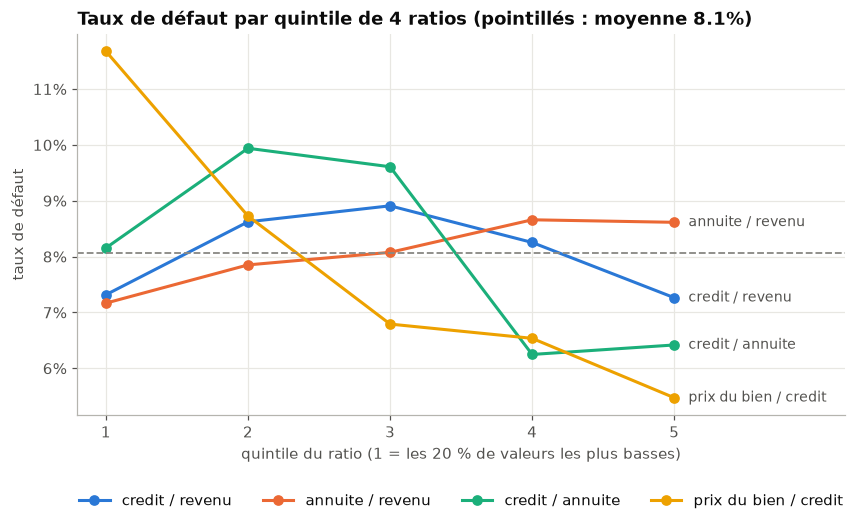

,mediane,taux_q1,taux_q2,taux_q3,taux_q4,taux_q5
credit / revenu,3.27,7.3%,8.6%,8.9%,8.3%,7.3%
annuite / revenu,0.16,7.2%,7.9%,8.1%,8.7%,8.6%
credit / annuite,20.00,8.2%,9.9%,9.6%,6.2%,6.4%
prix du bien / credit,0.89,11.7%,8.7%,6.8%,6.5%,5.5%


In [30]:
ratios = pd.DataFrame({
    "credit / revenu": train["AMT_CREDIT"] / train["AMT_INCOME_TOTAL"],
    "annuite / revenu": train["AMT_ANNUITY"] / train["AMT_INCOME_TOTAL"],
    "credit / annuite": train["AMT_CREDIT"] / train["AMT_ANNUITY"],   # nombre approximatif d'échéances
    "prix du bien / credit": train["AMT_GOODS_PRICE"] / train["AMT_CREDIT"],
})
quintiles = pd.DataFrame({
    nom: train.groupby(pd.qcut(ratio, 5, labels=range(1, 6), duplicates="drop"), observed=True)["TARGET"].mean()
    for nom, ratio in ratios.items()
})

fig, ax = plt.subplots(figsize=(9, 4.5))
for nom, couleur in zip(quintiles, [BLEU, ORANGE, VERT_D_EAU, JAUNE]):
    ax.plot(quintiles.index, quintiles[nom], marker="o", markersize=6, color=couleur, label=nom)
    ax.text(5.1, quintiles[nom].iloc[-1], nom, va="center", color="#52514e", fontsize=9)
ax.axhline(TAUX_MOYEN, color=GRIS, linestyle="--", linewidth=1.2)
ax.yaxis.set_major_locator(MultipleLocator(0.01))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xticks(range(1, 6))
ax.set_xlim(0.8, 6.2)
ax.set_xlabel("quintile du ratio (1 = les 20 % de valeurs les plus basses)")
ax.set_ylabel("taux de défaut")
ax.set_title(f"Taux de défaut par quintile de 4 ratios {MOYENNE}", loc="left")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=4)
plt.show()

tableau = quintiles.T.rename(columns=lambda q: f"taux_q{q}")
tableau.insert(0, "mediane", ratios.median())
afficher(tableau, {"mediane": "{:.2f}"})

- **Prix du bien / crédit** : le lien le plus net. Quand le crédit dépasse le prix du bien (ratio bas, frais et assurances financés),
  le taux de défaut monte à 11,7 %, contre 5,5 % quand une partie du bien est payée sans emprunt.
- **Annuité / revenu** (taux d'effort) : le risque augmente doucement avec la part du revenu consacrée au remboursement.
- **Crédit / annuité** (≈ nombre d'échéances) et **crédit / revenu** : lien **non monotone** (le risque monte puis redescend).
  Une régression logistique ne capte pas ce genre de forme sans transformation ; un arbre ou XGBoost, si.
- **Décision** : ces 4 ratios seront ajoutés à l'étape « nouvelles variables », et on mesurera ce qu'ils apportent.

## 9. L'historique de crédit : `bureau.csv`

Chaque ligne est un crédit du client chez **un autre organisme**, déclaré au bureau de crédit. Un client peut en avoir plusieurs, ou aucun.

In [31]:
bureau = pd.read_csv(DOSSIER_RAW / "bureau.csv")
print(f"{len(bureau):,} crédits, {bureau.shape[1]} colonnes, {bureau['SK_ID_CURR'].nunique():,} clients")
print("Statut :", bureau["CREDIT_ACTIVE"].value_counts().to_dict())
print("Type :", bureau["CREDIT_TYPE"].value_counts().head(5).to_dict())
bureau.head(3).T

1,716,428 crédits, 17 colonnes, 305,811 clients
Statut : {'Closed': 1079273, 'Active': 630607, 'Sold': 6527, 'Bad debt': 21}
Type : {'Consumer credit': 1251615, 'Credit card': 402195, 'Car loan': 27690, 'Mortgage': 18391, 'Microloan': 12413}


,0,1,2
SK_ID_CURR,215354,215354,215354
SK_ID_BUREAU,5714462,5714463,5714464
CREDIT_ACTIVE,Closed,Active,Active
CREDIT_CURRENCY,currency 1,currency 1,currency 1
DAYS_CREDIT,-497,-208,-203
CREDIT_DAY_OVERDUE,0,0,0
DAYS_CREDIT_ENDDATE,-153.0,1075.0,528.0
DAYS_ENDDATE_FACT,-153.0,NaN,NaN
AMT_CREDIT_MAX_OVERDUE,NaN,NaN,NaN
CNT_CREDIT_PROLONG,0,0,0


In [32]:
# On ne garde que les crédits des clients du jeu d'apprentissage
bureau_train = bureau[bureau["SK_ID_CURR"].isin(train["SK_ID_CURR"])]
par_client = bureau_train.groupby("SK_ID_CURR").agg(
    nb_credits=("SK_ID_BUREAU", "size"),
    nb_actifs=("CREDIT_ACTIVE", lambda s: (s == "Active").sum()),
    jours_depuis_dernier=("DAYS_CREDIT", "max"),
    retard_en_cours=("CREDIT_DAY_OVERDUE", "max"),
)
historique = train[["SK_ID_CURR", "TARGET"]].merge(par_client, on="SK_ID_CURR", how="left")
historique["nb_credits"] = historique["nb_credits"].fillna(0)

print(f"Crédits par client : médiane {historique['nb_credits'].median():.0f}, "
      f"maximum {historique['nb_credits'].max():.0f}")
aucun = historique["nb_credits"].eq(0).map({True: "aucun crédit déclaré", False: "au moins un crédit"})
afficher(taux_defaut(aucun.rename("historique"), historique))

Crédits par client : médiane 4, maximum 94


,prets,taux_defaut
historique,,
au moins un crédit,"210,764",7.7%
aucun crédit déclaré,"35,244",10.1%


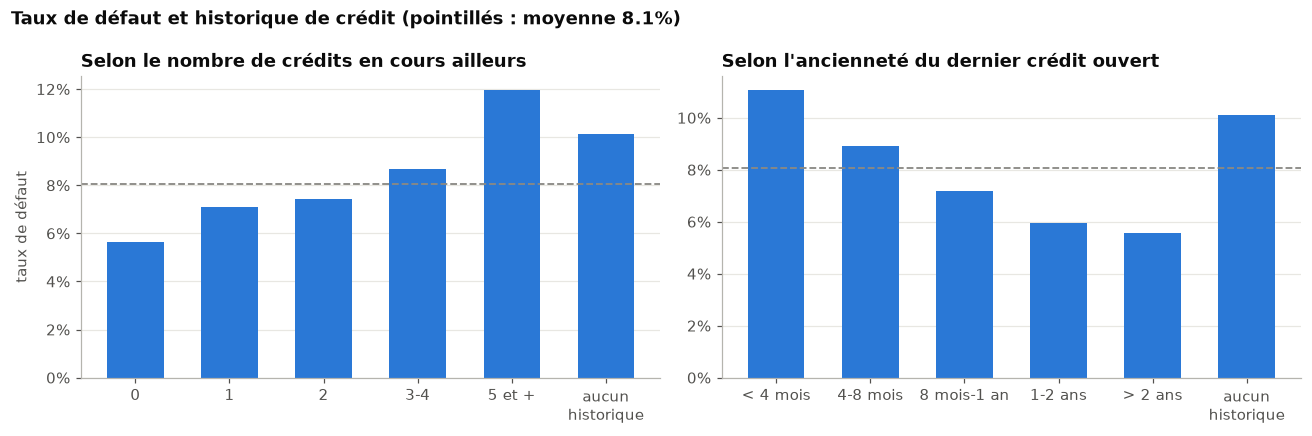

Clients avec un retard en cours sur un autre crédit : 2,706, taux de défaut 15.5%


In [33]:
nb_actifs = pd.cut(historique["nb_actifs"], [-1, 0, 1, 2, 4, 100], labels=["0", "1", "2", "3-4", "5 et +"])
nb_actifs = nb_actifs.cat.add_categories("aucun\nhistorique").fillna("aucun\nhistorique")
par_actifs = taux_defaut(nb_actifs, historique)

anciennete = pd.qcut(-historique["jours_depuis_dernier"], 5,
                     labels=["< 4 mois", "4-8 mois", "8 mois-1 an", "1-2 ans", "> 2 ans"])
anciennete = anciennete.cat.add_categories("aucun\nhistorique").fillna("aucun\nhistorique")
par_anciennete = taux_defaut(anciennete, historique)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(par_actifs.index.astype(str), par_actifs["taux_defaut"], color=BLEU, width=0.6)
axes[0].set_title("Selon le nombre de crédits en cours ailleurs", loc="left")
axes[1].bar(par_anciennete.index.astype(str), par_anciennete["taux_defaut"], color=BLEU, width=0.6)
axes[1].set_title("Selon l'ancienneté du dernier crédit ouvert", loc="left")
fig.suptitle(f"Taux de défaut et historique de crédit {MOYENNE}", x=0.01, ha="left", fontweight="bold")
for ax in axes:
    ax.axhline(TAUX_MOYEN, color=GRIS, linestyle="--", linewidth=1.2)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("taux de défaut")
plt.tight_layout()
plt.show()

print("Clients avec un retard en cours sur un autre crédit :",
      f"{(historique['retard_en_cours'] > 0).sum():,}, taux de défaut "
      f"{historique.loc[historique['retard_en_cours'] > 0, 'TARGET'].mean():.1%}")

In [34]:
print("Anomalies à traiter dans bureau.csv :")
print(f"- dette restante négative : {(bureau['AMT_CREDIT_SUM_DEBT'] < 0).sum():,} crédits")
print(f"- date de fin prévue la plus ancienne : {bureau['DAYS_CREDIT_ENDDATE'].min():,.0f} jours "
      f"(soit {-bureau['DAYS_CREDIT_ENDDATE'].min() / 365.25:.0f} ans avant la demande)")
print("- part de valeurs manquantes :", bureau.isna().mean()[lambda s: s > 0].round(2).sort_values(ascending=False).to_dict())

Anomalies à traiter dans bureau.csv :
- dette restante négative : 8,418 crédits
- date de fin prévue la plus ancienne : -42,060 jours (soit 115 ans avant la demande)
- part de valeurs manquantes : {'AMT_ANNUITY': 0.71, 'AMT_CREDIT_MAX_OVERDUE': 0.66, 'DAYS_ENDDATE_FACT': 0.37, 'AMT_CREDIT_SUM_LIMIT': 0.34, 'AMT_CREDIT_SUM_DEBT': 0.15, 'DAYS_CREDIT_ENDDATE': 0.06, 'AMT_CREDIT_SUM': 0.0}


- **14 % des clients n'ont aucun crédit déclaré** ailleurs, et leur taux de défaut est plus élevé (10,1 % contre 7,7 %) :
  c'est exactement la population « peu bancarisée » que vise Home Credit.
- **Plus de 4 crédits en cours ailleurs** : 11,9 % de défauts.
- **Un crédit ouvert il y a moins de 4 mois** : 11,1 % de défauts, contre 5,6 % si le dernier crédit date de plus de 2 ans.
  Ouvrir beaucoup de crédits récemment est un signal de besoin d'argent.
- **Un retard en cours sur un autre crédit** : 15,5 % de défauts (mais seulement 2 706 clients).
- **Décision** : agréger `bureau.csv` en une ligne par client (nombre de crédits, nombre actifs, ancienneté du dernier crédit,
  dette en cours, retards), avec un indicateur « aucun historique ». Ces agrégats n'utilisent pas `TARGET` :
  ils se calculent de la même façon pour un nouveau client, sans fuite de données.

## 10. Conclusions : règles de préparation pour la suite

| Sujet | Constat | Décision |
|---|---|---|
| Cible | 8,07 % de défauts ; « personne ne fait défaut » = 92 % d'accuracy | ROC AUC, découpage stratifié 80 / 20 (`random_state=42`), pondération des classes à tester |
| Colonnes sur l'immeuble | 47 colonnes, 47 à 70 % manquantes, versions AVG / MODE / MEDI corrélées à plus de 0,96 | garder les `_AVG` (+ `TOTALAREA_MODE` et les `_MODE` texte), retirer 28 colonnes |
| Valeurs manquantes | l'absence est informative (`EXT_SOURCE_3`, `AMT_REQ_CREDIT_BUREAU_*`) ou logique (`OWN_CAR_AGE`) | logistique : médiane + indicateur de valeur manquante ; XGBoost : valeurs manquantes gérées nativement |
| Dates | jours négatifs avant la demande | conversion en années positives (`AGE`, `ANCIENNETE_EMPLOI`…) |
| `DAYS_EMPLOYED = 365 243` | 18 % des prêts : retraités et chômeurs, moins de défauts | valeur manquante + indicateur `SANS_EMPLOI` |
| Revenus extrêmes | jusqu'à 117 millions, erreur de saisie probable | lignes conservées ; log des montants pour la logistique |
| Modalités rares | XNA, Unknown, étudiants, chefs d'entreprise… | regroupées par `OneHotEncoder(min_frequency=...)` |
| Colonnes presque constantes | `FLAG_MOBIL` + 9 `FLAG_DOCUMENT_*` | retirées |
| Sexe | prédictif (10,1 % contre 7,0 %), mais reflété par des proxies (métier, voiture) | exclu du modèle ; contrôle d'équité à la fin |
| Montants | crédit et prix du bien corrélés à 0,99 | ratios crédit / revenu, annuité / revenu, crédit / annuité, prix du bien / crédit |
| Historique de crédit | aucun historique, crédits récents ou nombreux = plus de défauts | agrégats de `bureau.csv` par client |

**Variables les plus prometteuses** : les trois scores externes, l'âge, le niveau d'études, le type de revenu, le métier,
la note de la région, le ratio prix du bien / crédit et l'historique de crédit.

**Prochaine étape** (notebook 02) : `src/prepare_data.py` applique ces règles, puis on calcule les baselines et une première régression logistique.